# Inferencia con YOLOv8n-seg finetuneado

Carga `runs/yolov8n-seg/weights/best.pt`, detecta peces en una imagen y dibuja la máscara predicha y la caja en rosa.

In [5]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO

IMG_PATH = Path(r"C:\Users\juanm\Documents\GitHub\fish_cv_pfc\example.jpg")   # <- cambiar por la imagen a procesar
WEIGHTS = Path("runs/yolov8n-seg/weights/best.pt").resolve()
CONF = 0.01
IMGSZ = 640
PINK = (255, 105, 180)   # RGB
ALPHA = 0.45             # opacidad de la máscara

model = YOLO(WEIGHTS)

9 pez/peces detectado(s) con conf >= 0.01


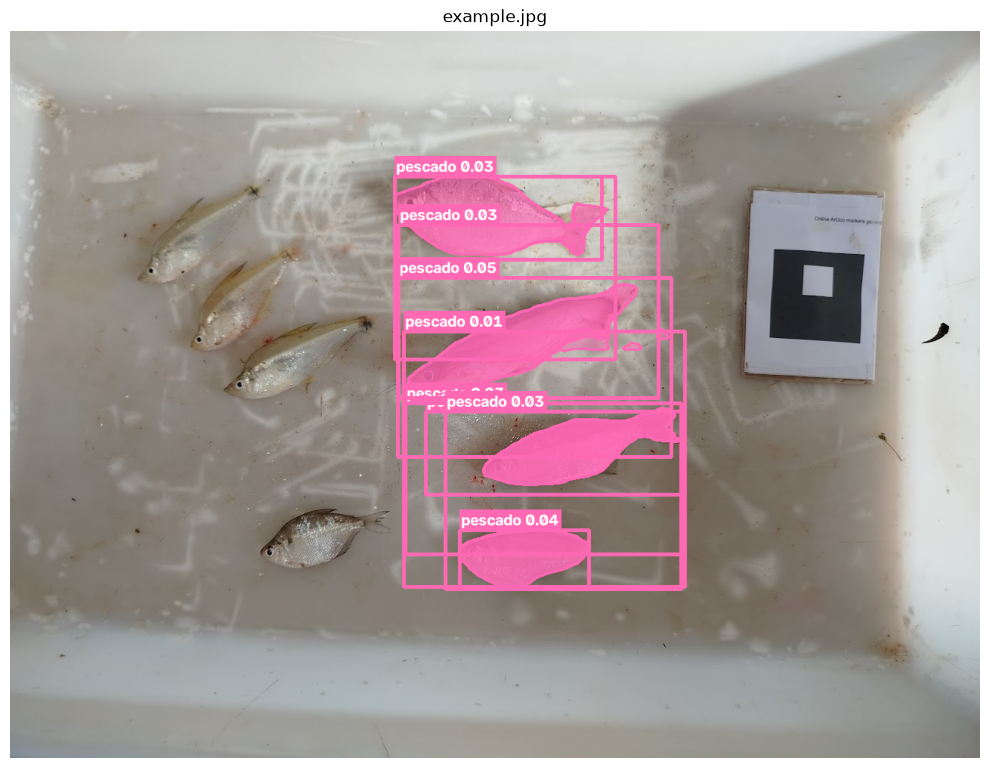

guardado en C:\Users\juanm\Documents\GitHub\fish_cv_pfc\runs\pred_example.png


In [6]:
# np.fromfile + imdecode: soporta rutas con caracteres no ASCII en Windows
img = cv2.imdecode(np.fromfile(str(IMG_PATH), np.uint8), cv2.IMREAD_COLOR)   # BGR
assert img is not None, f"No se pudo leer {IMG_PATH}"
h, w = img.shape[:2]

res = model.predict(img, imgsz=IMGSZ, conf=CONF, retina_masks=True, verbose=False)[0]

out = img.copy()
pink_bgr = PINK[::-1]
n = len(res.boxes)
for i in range(n):
    if res.masks is not None:
        m = res.masks.data[i].cpu().numpy().astype(bool)
        if m.shape != (h, w):
            m = cv2.resize(m.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
        out[m] = (out[m] * (1 - ALPHA) + np.array(pink_bgr) * ALPHA).astype(np.uint8)
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, cnts, -1, pink_bgr, 2)
    x0, y0, x1, y1 = res.boxes.xyxy[i].cpu().numpy().round().astype(int)
    cv2.rectangle(out, (x0, y0), (x1, y1), pink_bgr, 3)
    label = f"pescado {float(res.boxes.conf[i]):.2f}"
    (tw, th), bl = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
    cv2.rectangle(out, (x0, max(y0 - th - bl - 4, 0)), (x0 + tw + 4, max(y0, th + bl + 4)), pink_bgr, -1)
    cv2.putText(out, label, (x0 + 2, max(y0, th + bl + 4) - bl - 2), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)

print(f"{n} pez/peces detectado(s) con conf >= {CONF}" + ("" if n else " (nada que dibujar)"))
plt.figure(figsize=(10, 8)); plt.imshow(out[..., ::-1]); plt.axis("off"); plt.title(IMG_PATH.name)
plt.tight_layout(); plt.show()

OUT_PATH = Path("runs") / f"pred_{IMG_PATH.stem}.png"
cv2.imencode(".png", out)[1].tofile(str(OUT_PATH))
print("guardado en", OUT_PATH.resolve())